# Measuring a lens two ways: Shack-Hartmann versus phase diversity

How do we measure the aberrations of a lens? Two classic answers need no reference arm:

1. A **Shack-Hartmann sensor** looks at the beam itself. A lenslet array cuts the collimated wavefront into
   small patches and focuses each one onto a camera. Each spot moves by the focal length times the local
   slope of the wavefront. The wavefront follows from integrating the slopes.
2. **Phase diversity** looks at the focus. A camera records the PSF at a few known defocus positions, and
   the pupil phase is fitted until the model PSFs match the recorded ones (notebook 28).

This notebook measures one ray-traced lens both ways and compares both results with the true Zernike
coefficients of the trace. It ties together `raytrace` (the lens and its exit pupil), the new
`shack_hartmann` module (spot images, centroids, modal and zonal reconstruction), `phase_retrieval`
(through-focus PSFs and the fit), `processing.CameraNoiser` (photon and read noise) and `bases` (Fringe
Zernikes).

| `pyoptics.shack_hartmann` | Purpose |
|---|---|
| `ShackHartmann(n_lenslets, pitch, focal_length, wavelength, pixels)` | sensor geometry; Fresnel number, sensitivity (`slope_per_pixel`) and dynamic range (`max_slope`) |
| `.field(phase, amplitude)` | field on the lenslets from a pupil phase on normalized pupil coordinates (e.g. `raytrace.Pupil`) |
| `.spots(field)` | camera image: the Fraunhofer pattern of every lenslet in its own pixel window |
| `.slopes(image, reference)` | thresholded centroids, optionally relative to a calibration image |
| `.model_slopes()`, `.zernike_matrix()` | ideal slopes: the intensity weighted mean gradient over each lenslet |
| `.reconstruct_zernikes()`, `.reconstruct_zonal()` | modal least squares fit of Zernike gradients; Southwell's zonal integration |

Conventions: lengths in mm, the pupil phase is $+2\pi\,\mathrm{OPD}/\lambda$ as in `raytrace`, and Zernikes are
Fringe Zernikes in waves on the unit pupil.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from pyoptics import raytrace as rt
from pyoptics import phase_retrieval as pr
from pyoptics.bases import fringe_zernike
from pyoptics.processing import CameraNoiser
from pyoptics.shack_hartmann import ShackHartmann
from pyoptics.utils import grid1d

plt.rcParams["figure.dpi"] = 100
WL = 587.5618e-6                 # d line in mm
BK7 = (1.5168, 64.17)            # (n_d, V_d)
FIELD = np.radians(2.0)
J = list(range(2, 16))           # the compared Fringe Zernikes Z2...Z15


def true_zernikes(pup, n_terms=36, N=201):
    # least squares fit to the traced pupil phase on the imaging pupil coordinates (where the pupil is lit)
    p = np.linspace(-1, 1, N)
    PX, PY = np.meshgrid(p, p)
    ok = (PX**2 + PY**2 <= 1) & (pup.mask(PX, PY) > 0.5)
    A = np.column_stack([fringe_zernike(j, PX[ok], PY[ok]) for j in range(1, n_terms + 1)])
    c = np.linalg.lstsq(A, pup.phase(PX[ok], PY[ok])/(2*np.pi), rcond=None)[0]
    return dict(zip(range(1, n_terms + 1), c))


_p = np.linspace(-1, 1, 101)
_PX, _PY = np.meshgrid(_p, _p)
_disk = _PX**2 + _PY**2 <= 1
_Z = {j: fringe_zernike(j, _PX[_disk], _PY[_disk]) for j in J}


def error(c, truth):
    # rms wavefront error (waves) of the Z2...Z15 part of c relative to the truth, over the unit pupil
    d = sum((c[j] - truth[j])*_Z[j] for j in J)
    return np.sqrt(np.mean((d - d.mean())**2))


def phase_map(pup, coeffs=None, N=129):
    # traced pupil phase (or a Zernike sum) in waves on the unit disk, NaN outside
    p = np.linspace(-1, 1, N)
    PX, PY = np.meshgrid(p, p)
    ok = (PX**2 + PY**2 <= 1) & (pup.mask(PX, PY) > 0.5)
    if coeffs is None:
        W = pup.phase(PX, PY)/(2*np.pi)
    else:
        W = sum(c*fringe_zernike(j, PX, PY) for j, c in coeffs.items())
    return np.where(ok, W, np.nan)


def show(ax, img, title, cmap="RdBu_r", symmetric=True, label="waves", extent=(-1, 1, -1, 1)):
    vmax = np.nanmax(np.abs(img)) if symmetric else None
    im = ax.imshow(img, origin="lower", cmap=cmap, extent=extent,
                   vmin=-vmax if symmetric else None, vmax=vmax)
    ax.set_title(title, fontsize=9)
    plt.colorbar(im, ax=ax, shrink=0.8, label=label)

## 1 The lens under test

The test piece is the plano-convex BK7 singlet of notebook 19 with the plane side towards the collimated
beam (the "wrong" way round), f = 100 mm at f/10 and a field of 2°. The image plane is moved from the
paraxial focus to the best focus (smallest rms OPD), as one would align a real test. What remains is
spherical aberration, coma, a little astigmatism and the tilt of the chief ray reference.

best focus -0.674 mm from the paraxial image; rms OPD 0.150 waves, Strehl 0.44
image space NA of the traced pupil: 0.0506


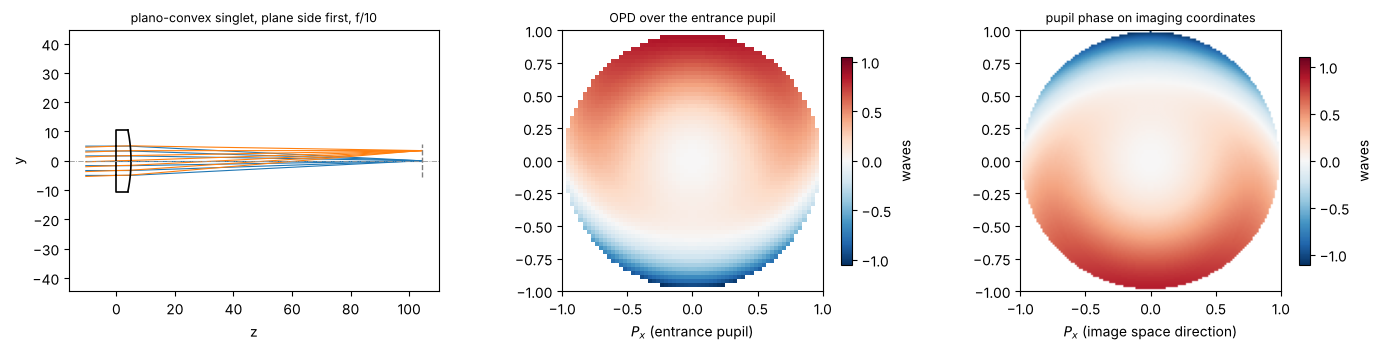

In [2]:
R1 = 100*(BK7[0] - 1)


def singlet(entrance_pupil_radius):
    s = [rt.Surface(np.inf, 5.0, material=BK7, semi_diameter=10.5),
         rt.Surface(-R1, 95.0, n_after=1.0, semi_diameter=10.5)]
    return rt.System(s, 0, WL, field_angle=FIELD, entrance_pupil_radius=entrance_pupil_radius).at_paraxial_focus()


lens_paraxial = singlet(5.0)
d0 = lens_paraxial.surfaces[-1].thickness
d_best = minimize_scalar(lambda d: lens_paraxial.with_image_distance(d).rms_opd(FIELD, N=33),
                         bracket=(d0 - 1.0, d0)).x
lens = lens_paraxial.with_image_distance(d_best)
pup = lens.pupil(FIELD, N=64)
truth = true_zernikes(pup)

print(f"best focus {d_best - d0:+.3f} mm from the paraxial image; rms OPD {lens.rms_opd(FIELD):.3f} waves, "
      f"Strehl {lens.strehl(FIELD):.2f}")
print(f"image space NA of the traced pupil: {pup.NA:.4f}")

fig = plt.figure(figsize=(14, 3.6))
ax = fig.add_subplot(1, 3, 1)
lens.draw(ax, fields=[0.0, FIELD], n_rays=7)
ax.set_title("plano-convex singlet, plane side first, f/10", fontsize=9)
show(fig.add_subplot(1, 3, 2), lens.opd(FIELD, 64).W, "OPD over the entrance pupil")
show(fig.add_subplot(1, 3, 3), phase_map(pup), "pupil phase on imaging coordinates")
fig.axes[1].set_xlabel("$P_x$ (entrance pupil)")
fig.axes[3].set_xlabel("$P_x$ (image space direction)")
plt.tight_layout()

Two pupil coordinate systems appear here. `System.opd()` and `System.zernike()` use normalized coordinates in
the **entrance pupil**. `System.pupil()` resamples the phase onto the coordinates of `imaging`: the image space
ray direction relative to the chief ray, $(P_x, P_y) = n'(d_x, d_y)/\mathrm{NA}$. A ray that enters at the top
of the pupil travels downwards behind a positive lens, so the map is turned by 180°. All odd Zernikes (tilt,
coma) change sign, and the slight pupil distortion at 2° changes the coefficients by a few milliwaves.

Both sensors see the second kind of coordinates. Phase diversity works with the PSF, which is the Fourier
transform of the pupil on exactly these coordinates. The Shack-Hartmann sensor sits behind an aplanatic
collimator that re-collimates the focus. Such a collimator maps the ray direction sines linearly onto beam
heights, so the beam on the lenslets is the same pupil, scaled. The "true" coefficients below are therefore
the fit of Z1...Z36 to the traced phase on imaging coordinates.

In [3]:
c_ep = lens.zernike(FIELD, 16, N=64)
print(" j   entrance pupil   imaging pupil (truth)")
for j in range(2, 17):
    print(f"{j:2d}   {c_ep[j - 1]:+9.4f}        {truth[j]:+9.4f}")
print(f"Z16...Z36 together: {np.sqrt(sum(truth[j]**2 for j in range(16, 37))):.4f} waves rms")

 j   entrance pupil   imaging pupil (truth)
 2     +0.0000          +0.0000
 3     +0.6606          -0.6691
 4     -0.0058          -0.0095
 5     +0.1063          +0.1035
 6     -0.0000          -0.0000
 7     +0.0000          -0.0000
 8     +0.3307          -0.3286
 9     -0.1928          -0.1947
10     +0.0000          +0.0000
11     +0.0001          -0.0002
12     -0.0000          -0.0017
13     +0.0000          +0.0000
14     -0.0000          +0.0000
15     +0.0002          +0.0038
16     -0.0001          +0.0016
Z16...Z36 together: 0.0016 waves rms


## 2 The Shack-Hartmann measurement

The sensor has 16 × 16 lenslets of 150 µm pitch and 15 mm focal length in front of a camera with 16 × 16
pixels (9.4 µm) per lenslet. The collimated beam is 2.4 mm wide and fills the circle inscribed in the
array. Two numbers describe the design:

- the **sensitivity**, the slope that moves a spot by one pixel, `slope_per_pixel` = pixel/f;
- the **dynamic range**, the slope that moves a spot to the edge of its window, `max_slope` = pitch/(2f).

A long focal length makes the sensor more sensitive and reduces its range. The spot size λf/pitch should
cover a few pixels, otherwise the centroids lock to the pixel grid. The Fresnel number pitch²/(λf) of a
lenslet sets how many field samples per lenslet the simulation needs.

In [4]:
sh = ShackHartmann(16, 0.15, 15.0, WL, pixels=16, pupil_radius=1.2)
print(sh)
print(f"Fresnel number {sh.fresnel_number:.2f}, {sh.samples} field samples per lenslet")
print(f"spot size lambda*f/pitch = {WL*sh.focal_length/sh.pitch*1e3:.1f} um = "
      f"{WL*sh.focal_length/sh.pitch/sh.pixel_size:.1f} pixels")
print(f"1 pixel = slope {sh.slope_per_pixel:.2e} = {sh.slope_per_pixel*sh.pupil_radius/WL:.2f} waves of tilt "
      f"over the pupil radius")
print(f"dynamic range: slope {sh.max_slope:.2e} = {sh.max_slope*sh.pupil_radius/WL:.1f} waves of tilt "
      f"over the pupil radius")

t0 = time.time()
image = sh.spots(sh.field(pup.phase, pup.mask))
slopes = sh.slopes(image, threshold=0.1, min_flux=0.5)
c_sh = sh.reconstruct_zernikes(slopes, 15, amplitude=pup.mask)
W_zonal = sh.reconstruct_zonal(slopes)
print(f"{slopes.valid.sum()} valid lenslets; simulation and reconstruction in {time.time() - t0:.2f} s")

ShackHartmann(16 x 16 lenslets, pitch 0.15, f 15, 16 pixels, pupil radius 1.2)
Fresnel number 2.55, 16 field samples per lenslet
spot size lambda*f/pitch = 58.8 um = 6.3 pixels
1 pixel = slope 6.25e-04 = 1.28 waves of tilt over the pupil radius
dynamic range: slope 5.00e-03 = 10.2 waves of tilt over the pupil radius


204 valid lenslets; simulation and reconstruction in 0.88 s


The camera image is a grid of nearly identical spots. The largest displacements, at the top rim, are
about 3.5 pixels, less than half of what the window of ±8 pixels allows. The quiver plot (right) magnifies
them. The pattern is the gradient of the wavefront: the tilt of the chief ray
reference plus the cubic shape of coma and the radial pull of spherical aberration. Lenslets at the rim are
only partly lit. Their spots are wider, and they count as valid if they receive at least half the light of a
full lenslet (`min_flux`). The model in `zernike_matrix()` weights the gradient with the intensity over each
lenslet, so these partial lenslets are described correctly.

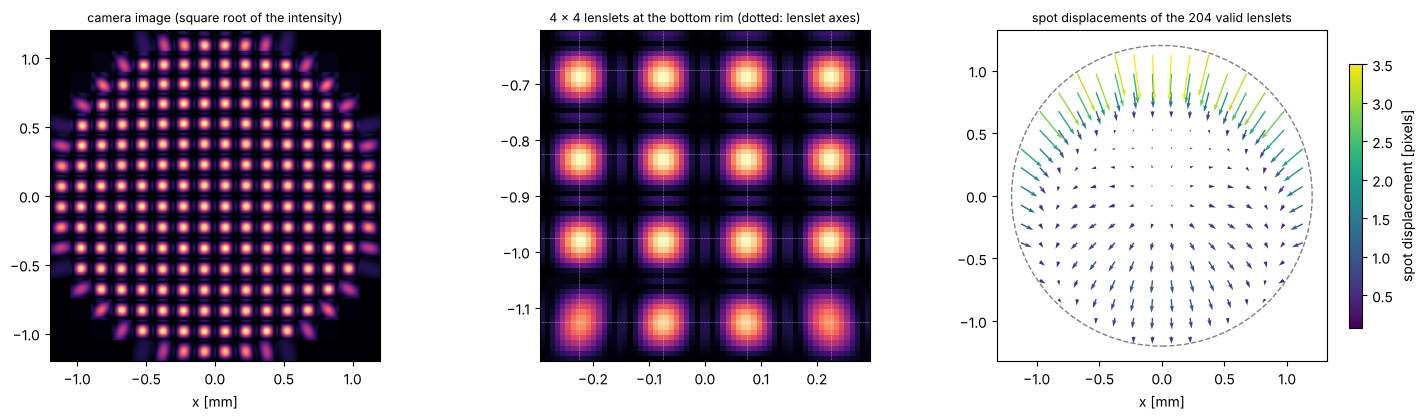

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
n_pix = sh.n_lenslets*sh.pixels
ext = np.array([-1, 1, -1, 1])*sh.n_lenslets*sh.pitch/2
axes[0].imshow(np.sqrt(image), origin="lower", cmap="magma", extent=ext)
axes[0].set_title("camera image (square root of the intensity)", fontsize=9)
axes[0].set_xlabel("x [mm]")
rim = (slice(0, 4*sh.pixels), slice(6*sh.pixels, 10*sh.pixels))
axes[1].imshow(np.sqrt(image[rim]), origin="lower", cmap="magma",
               extent=[sh.x[6*sh.samples], sh.x[10*sh.samples - 1], sh.y[0], sh.y[4*sh.samples - 1]])
for c in sh.centers:
    axes[1].axvline(c, color="w", lw=0.4, ls=":")
    axes[1].axhline(c, color="w", lw=0.4, ls=":")
axes[1].set_xlim(sh.x[6*sh.samples], sh.x[10*sh.samples - 1])
axes[1].set_ylim(sh.y[0], sh.y[4*sh.samples - 1])
axes[1].set_title("4 × 4 lenslets at the bottom rim (dotted: lenslet axes)", fontsize=9)
C_x, C_y = np.meshgrid(sh.centers, sh.centers)
v = slopes.valid
px = sh.slope_per_pixel
q = axes[2].quiver(C_x[v], C_y[v], slopes.sx[v]/px, slopes.sy[v]/px, np.hypot(slopes.sx, slopes.sy)[v]/px,
                   cmap="viridis", angles="xy")
plt.colorbar(q, ax=axes[2], shrink=0.8, label="spot displacement [pixels]")
axes[2].add_patch(plt.Circle((0, 0), sh.pupil_radius, fill=False, color="0.5", ls="--"))
axes[2].set_aspect("equal")
axes[2].set_title(f"spot displacements of the {v.sum()} valid lenslets", fontsize=9)
axes[2].set_xlabel("x [mm]")
plt.tight_layout()

The modal reconstruction fits the gradients of Z2...Z15 to the 2 × 196 slopes. The zonal reconstruction
(Southwell) needs no basis: it integrates the slopes on the lenslet grid. It returns the wavefront only at
the lenslet centres, but it also contains everything a 15-term fit would miss.

modal fit, Z2...Z15: wavefront error 2.8 mλ rms


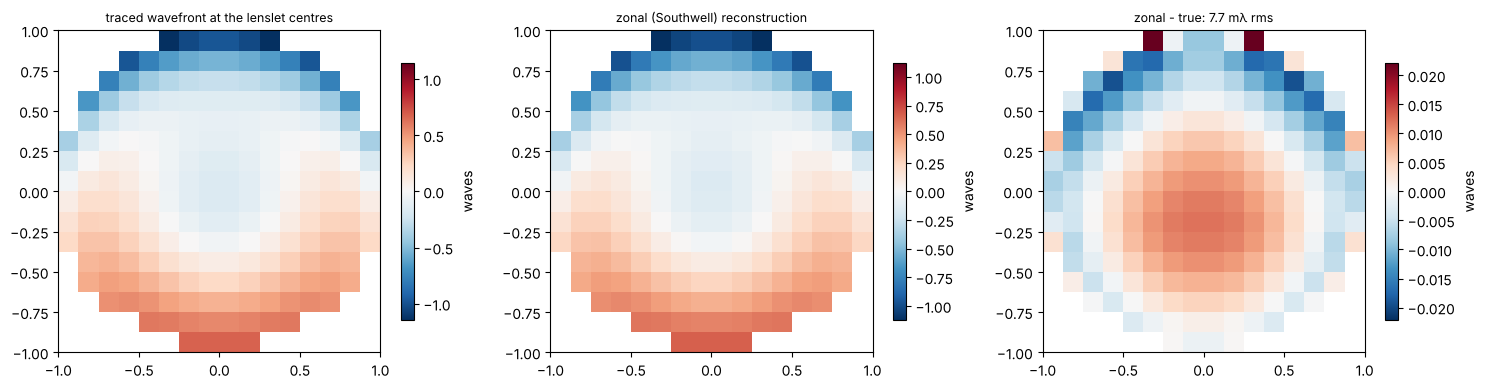

In [6]:
C_Px, C_Py = C_x/sh.pupil_radius, C_y/sh.pupil_radius
W_true_centres = np.where(v, pup.phase(C_Px, C_Py)/(2*np.pi), np.nan)
W_true_centres -= np.nanmean(W_true_centres)
d_zonal = W_zonal - W_true_centres

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ext = (-1, 1, -1, 1)
show(axes[0], W_true_centres, "traced wavefront at the lenslet centres", extent=ext)
show(axes[1], W_zonal, "zonal (Southwell) reconstruction", extent=ext)
show(axes[2], d_zonal, f"zonal - true: {np.sqrt(np.nanmean(d_zonal**2))*1e3:.1f} mλ rms", extent=ext)
plt.tight_layout()

print(f"modal fit, Z2...Z15: wavefront error {error(c_sh, truth)*1e3:.1f} mλ rms")

## 3 The phase diversity measurement

For phase diversity, a camera on a focus stage records the PSF at three positions. With the image space NA of
0.05, a defocus of ±0.75 waves of Z4 is a stage travel of about ±0.7 mm (`defocus_to_waves()`). The camera
pixels are 2.9 µm = λ/(4 NA), Nyquist sampling for the intensity, and the camera sees 64 × 64 pixels.
To avoid testing the retrieval on data from exactly its own model, the PSFs are computed with a four times
larger window (a finer sampled pupil, 256 × 256 pixels) and cropped to the 64 × 64 camera. The retrieval
then models the camera window as periodic and the pupil with 16 samples across its radius.

`phase_diversity()` fits Z2...Z15 (`method="fit"`, from a zero start), and the Gerchberg-Saxton variant
(`method="gs"`) retrieves the phase point by point.

focus stage positions: [ 0.689 -0.    -0.689] mm; energy inside the camera window: [0.976 0.987 0.988]


fit: 1.8 mλ rms in 1.7 s; Gerchberg-Saxton: 1.8 mλ rms in 0.8 s


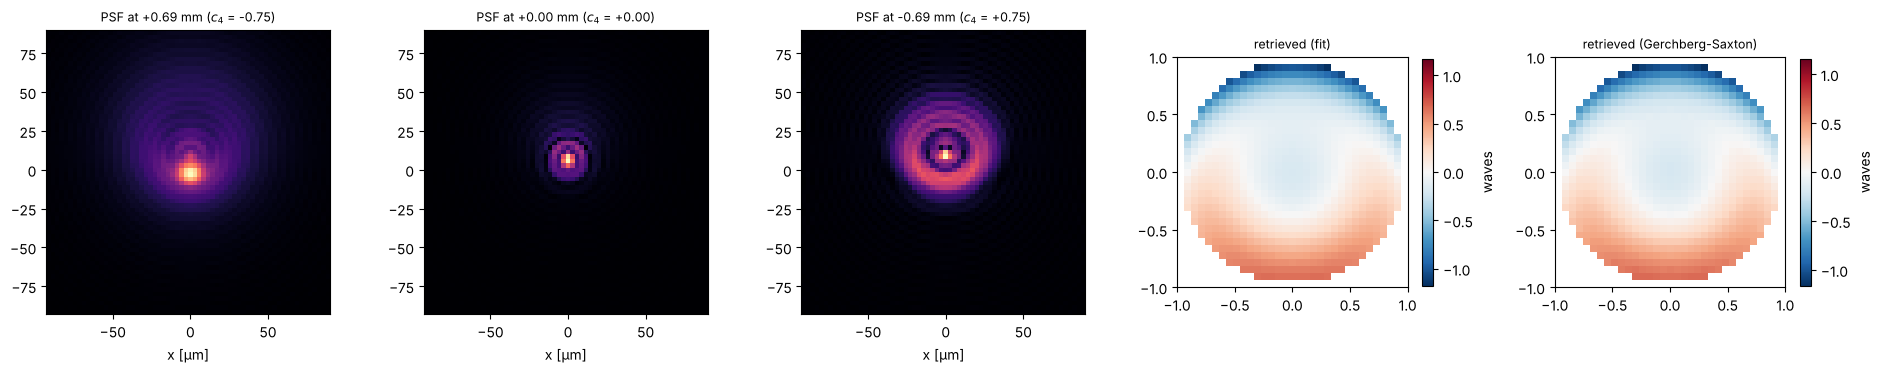

In [7]:
k, NA = pup.k, pup.NA
N_cam, oversize = 64, 4
dx = WL/(4*NA)
x_cam = grid1d(-N_cam*dx/2, N_cam*dx/2, N_cam)
x_sim = grid1d(-oversize*N_cam*dx/2, oversize*N_cam*dx/2, oversize*N_cam)
crop = slice((oversize - 1)*N_cam//2, (oversize + 1)*N_cam//2)
assert np.allclose(x_sim[crop], x_cam)

c4 = np.array([-0.75, 0.0, 0.75])
dz = c4/pr.defocus_to_waves(1.0, NA, k)                       # stage positions in mm
psfs = pr.diversity_psfs(x_sim, x_sim, NA, k, pupil_mask=pup.mask, phase=pup.phase, defocus_z=dz)[:, crop, crop]
print("focus stage positions:", np.round(dz, 3), "mm;",
      "energy inside the camera window:", np.round(psfs.sum(axis=(1, 2)), 3))

t0 = time.time()
res_fit = pr.phase_diversity(psfs, None, x_cam, x_cam, NA, k, n_zernike=15, pupil_mask=pup.mask, defocus_z=dz)
t_fit = time.time() - t0
t0 = time.time()
res_gs = pr.phase_diversity(psfs, None, x_cam, x_cam, NA, k, n_zernike=15, pupil_mask=pup.mask, defocus_z=dz,
                            method="gs", N_iter=300)
t_gs = time.time() - t0
print(f"fit: {error(res_fit.zernikes, truth)*1e3:.1f} mλ rms in {t_fit:.1f} s; "
      f"Gerchberg-Saxton: {error(res_gs.zernikes, truth)*1e3:.1f} mλ rms in {t_gs:.1f} s")

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
ext_um = np.array([x_cam[0], x_cam[-1], x_cam[0], x_cam[-1]])*1e3
for ax, p, c, z in zip(axes, psfs, c4, dz):
    ax.imshow(np.sqrt(p), origin="lower", cmap="magma", extent=ext_um)
    ax.set_title(f"PSF at {z + 0.0:+.2f} mm ($c_4$ = {c:+.2f})", fontsize=9)
    ax.set_xlabel("x [µm]")
inside = res_fit.support
pupil_ext = (-1, 1, -1, 1)
P = np.fft.fftshift(np.fft.fftfreq(N_cam, dx))*2*np.pi/(k*NA)
sl = np.abs(P) <= 1.05
show(axes[3], np.where(inside, res_fit.phase/(2*np.pi), np.nan)[np.ix_(sl, sl)], "retrieved (fit)",
     extent=(P[sl][0], P[sl][-1], P[sl][0], P[sl][-1]))
show(axes[4], np.where(inside, res_gs.phase/(2*np.pi), np.nan)[np.ix_(sl, sl)], "retrieved (Gerchberg-Saxton)",
     extent=(P[sl][0], P[sl][-1], P[sl][0], P[sl][-1]))
plt.tight_layout()

## 4 Head to head

Both methods recover the coefficients of the lens to a few milliwaves. The bar chart shows the
coefficients, the lower panel the errors. The Shack-Hartmann errors come from the sensor itself: the
finite pixel windows and the threshold bias the centroids slightly, and the partly lit lenslets at the rim
are the least accurate. The phase diversity errors come from the camera window: the PSF tails outside the
64 × 64 pixels are missing, and the model wraps them around. The Gerchberg-Saxton result is limited by its
slow convergence and by the coarse pupil sampling (16 pixels across the radius).

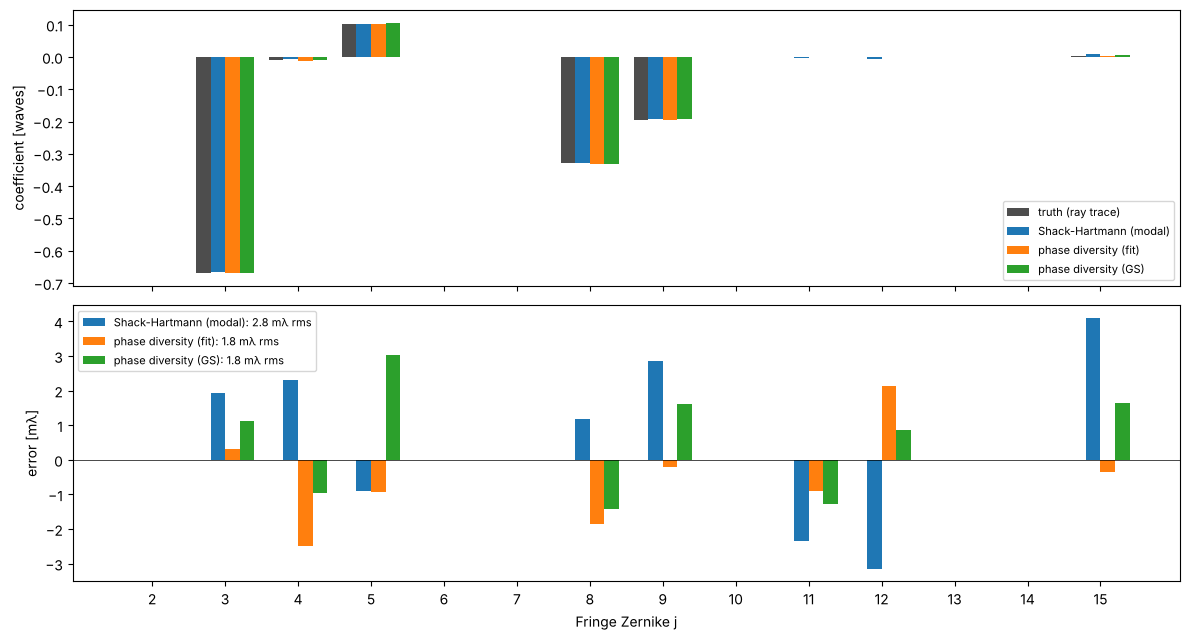

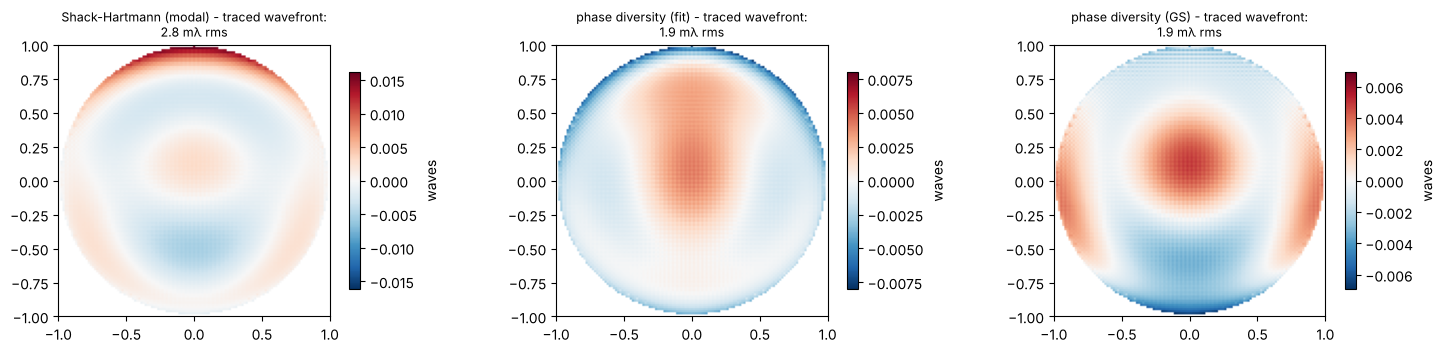

In [8]:
results = {"Shack-Hartmann (modal)": c_sh, "phase diversity (fit)": res_fit.zernikes,
           "phase diversity (GS)": res_gs.zernikes}
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
w = 0.2
axes[0].bar(np.array(J) - 1.5*w, [truth[j] for j in J], w, color="0.3", label="truth (ray trace)")
for i, (name, c) in enumerate(results.items()):
    axes[0].bar(np.array(J) + (i - 0.5)*w, [c[j] for j in J], w, label=name)
    axes[1].bar(np.array(J) + (i - 0.5)*w, [1e3*(c[j] - truth[j]) for j in J], w,
                label=f"{name}: {error(c, truth)*1e3:.1f} mλ rms")
axes[0].set_ylabel("coefficient [waves]")
axes[0].legend(fontsize=8)
axes[1].set_ylabel("error [mλ]")
axes[1].set_xlabel("Fringe Zernike j")
axes[1].set_xticks(J)
axes[1].axhline(0, color="k", lw=0.5)
axes[1].legend(fontsize=8)
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
W_ref = phase_map(pup)
for ax, (name, c) in zip(axes, results.items()):
    d = phase_map(pup, {j: c[j] for j in J}) - W_ref
    d -= np.nanmean(d)
    show(ax, d, f"{name} - traced wavefront:\n{np.sqrt(np.nanmean(d**2))*1e3:.1f} mλ rms")
plt.tight_layout()

The residual maps compare the 15-term reconstructions with the full traced wavefront. They also contain the
part of the lens that Z2...Z15 cannot describe (Z16 and above, mostly secondary spherical aberration), which
is the same for all methods.

## 5 Noise

So far, the cameras were noise free. Now both get the same total number of photons, a linear camera with
quantum efficiency 1 and 3 e⁻ read noise (`CameraNoiser`). For phase diversity, the photons are split over the
three PSFs. The fit starts once from zero and once from the Shack-Hartmann result. Each point is the mean of
two noise realizations.

59 s
Shack-Hartmann                              129.9       7.0       3.2       2.7 mλ
phase diversity, zero start                 508.2       2.4       1.7       1.8 mλ
phase diversity, Shack-Hartmann start        13.0       2.4       1.7       1.8 mλ


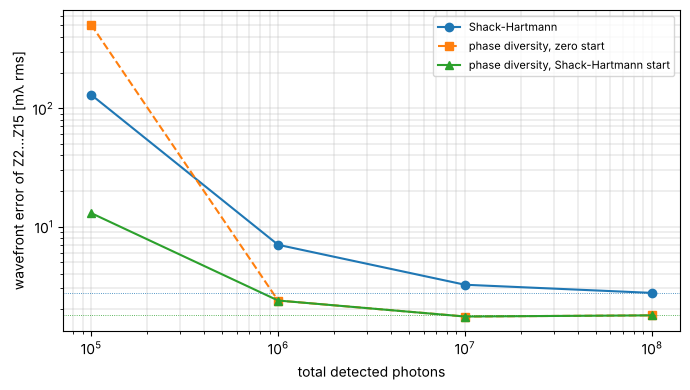

In [9]:
photons = [1e5, 1e6, 1e7, 1e8]
seeds = [1, 2]
runs = {"Shack-Hartmann": [], "phase diversity, zero start": [], "phase diversity, Shack-Hartmann start": []}
t0 = time.time()
for n_ph in photons:
    e = {name: [] for name in runs}
    for seed in seeds:
        cam = CameraNoiser("camera", read_noise=3.0, rng=seed)
        c_noisy = sh.reconstruct_zernikes(sh.slopes(cam(n_ph*image)), 15, amplitude=pup.mask)
        e["Shack-Hartmann"].append(error(c_noisy, truth))
        noisy = np.array([cam(n_ph/len(psfs)*p/p.sum()) for p in psfs])
        for name, start in (("phase diversity, zero start", None),
                            ("phase diversity, Shack-Hartmann start", c_noisy)):
            r = pr.phase_diversity(noisy, None, x_cam, x_cam, NA, k, n_zernike=15, pupil_mask=pup.mask,
                                   defocus_z=dz, start=start)
            e[name].append(error(r.zernikes, truth))
    for name in runs:
        runs[name].append(np.mean(e[name]))
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 4))
for (name, e), m in zip(runs.items(), ("o-", "s--", "^-")):
    ax.loglog(photons, 1e3*np.array(e), m, label=name)
ax.axhline(1e3*error(c_sh, truth), color="C0", lw=0.6, ls=":")
ax.axhline(1e3*error(res_fit.zernikes, truth), color="C2", lw=0.6, ls=":")
ax.set_xlabel("total detected photons")
ax.set_ylabel("wavefront error of Z2...Z15 [mλ rms]")
ax.legend(fontsize=8)
ax.grid(True, which="both", lw=0.3)
plt.tight_layout()
for name, e in runs.items():
    print(f"{name:40s}", "  ".join(f"{1e3*v:8.1f}" for v in e), "mλ")

At 10⁵ photons, neither method works well on its own. Each lenslet gets about 500 photons, spread over
256 pixels that each add 3 e⁻ of read noise, and the Shack-Hartmann error grows to about a tenth of a wave.
The fit of phase diversity from a zero start is led into a wrong local minimum by the noise. Started from
the Shack-Hartmann result, the same fit is ten times more accurate than the Shack-Hartmann sensor alone.
From 10⁶ photons on, both converge, and phase diversity is two to three times more accurate at the same
photon number: it uses every photon of three compact PSFs, while the sensor divides them over 200 spots.
At high light levels both approach their noise-free limits of section 4 (dotted lines).

## 6 Dynamic range

A faster version of the same lens shows the other side of the trade-off: f/8 instead of f/10, and the camera
left at the paraxial focus. The wavefront error grows to about one wave rms, dominated by defocus,
spherical aberration and coma.

f/8 at the paraxial focus: rms OPD 0.98 waves
Z2...Z9: -0.00  -1.28  -1.66  +0.16  -0.00  +0.00  -0.62  -0.46


Shack-Hartmann f = 15.0 mm: largest slope 1.60 x max_slope, error   72.7 mλ rms


Shack-Hartmann f =  6.0 mm: largest slope 0.64 x max_slope, error    1.8 mλ rms


energy inside the 128 x 128 camera window: [0.96  0.983 0.99 ]


phase diversity, zero start           : error  1340.2 mλ rms (181 evaluations, 40.4 s)


phase diversity, Shack-Hartmann start : error     7.3 mλ rms (11 evaluations, 3.0 s)


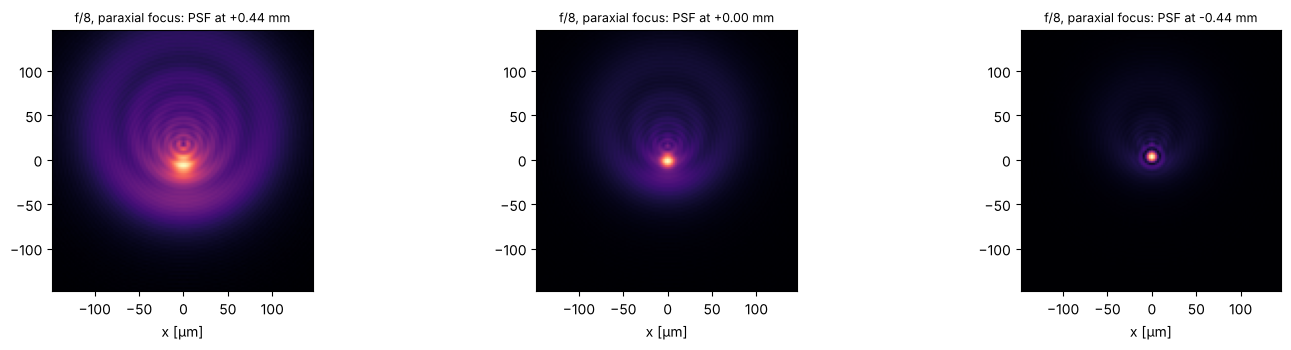

In [10]:
lens_fast = singlet(6.25)
pup_fast = lens_fast.pupil(FIELD, N=64)
truth_fast = true_zernikes(pup_fast)
print(f"f/8 at the paraxial focus: rms OPD {lens_fast.rms_opd(FIELD):.2f} waves")
print("Z2...Z9:", "  ".join(f"{truth_fast[j]:+.2f}" for j in range(2, 10)))

for f, pixels in ((15.0, 16), (6.0, 24)):
    s = ShackHartmann(16, 0.15, f, WL, pixels=pixels, pupil_radius=1.2)
    gx, gy = s.model_slopes(pup_fast.phase, pup_fast.mask)
    c = s.reconstruct_zernikes(s.slopes(s.spots(s.field(pup_fast.phase, pup_fast.mask))), 15, amplitude=pup_fast.mask)
    if f == 6.0:
        sh_fast, c_sh_fast = s, c
    print(f"Shack-Hartmann f = {f:4.1f} mm: largest slope {np.nanmax(np.hypot(gx, gy))/s.max_slope:.2f} x max_slope, "
          f"error {error(c, truth_fast)*1e3:6.1f} mλ rms")

NA_f, k_f = pup_fast.NA, pup_fast.k
dx_f = WL/(4*NA_f)
N_f = 128                      # the defocused PSFs are larger: twice the camera window of section 3
x_cam_f = grid1d(-N_f*dx_f/2, N_f*dx_f/2, N_f)
x_sim_f = grid1d(-oversize*N_f*dx_f/2, oversize*N_f*dx_f/2, oversize*N_f)
crop_f = slice((oversize - 1)*N_f//2, (oversize + 1)*N_f//2)
dz_f = c4/pr.defocus_to_waves(1.0, NA_f, k_f)
psfs_f = pr.diversity_psfs(x_sim_f, x_sim_f, NA_f, k_f, pupil_mask=pup_fast.mask, phase=pup_fast.phase,
                           defocus_z=dz_f)[:, crop_f, crop_f]
print("energy inside the 128 x 128 camera window:", np.round(psfs_f.sum(axis=(1, 2)), 3))
for name, start in (("zero start", None), ("Shack-Hartmann start", c_sh_fast)):
    t0 = time.time()
    r = pr.phase_diversity(psfs_f, None, x_cam_f, x_cam_f, NA_f, k_f, n_zernike=15, pupil_mask=pup_fast.mask,
                           defocus_z=dz_f, start=start)
    print(f"phase diversity, {name:21s}: error {error(r.zernikes, truth_fast)*1e3:7.1f} mλ rms "
          f"({len(r.errors)} evaluations, {time.time() - t0:.1f} s)")
    if start is None:
        res_fast_zero = r

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, p, z in zip(axes, psfs_f, dz_f):
    ax.imshow(np.sqrt(p), origin="lower", cmap="magma",
              extent=np.array([x_cam_f[0], x_cam_f[-1], x_cam_f[0], x_cam_f[-1]])*1e3)
    ax.set_title(f"f/8, paraxial focus: PSF at {z + 0.0:+.2f} mm", fontsize=9)
    ax.set_xlabel("x [µm]")
plt.tight_layout()

With f = 15 mm, the steepest slopes at the rim exceed `max_slope` by 60 %. The spots of the outer lenslets
leave their windows, their light is lost or lands in the wrong window, and the error grows to several
hundredths of a wave. A sensor with f = 6 mm (and 24 pixels per lenslet, so that the smaller spots stay
sampled) has 2.5 times the range and measures the lens to about 2 mλ again. The price is a 2.5 times
lower sensitivity per pixel.

Phase diversity has no such hard limit, as long as the PSFs fit into the camera window (here 128 × 128
pixels). But its fit is nonlinear. From a zero start it ends in a wrong local minimum, more than a wave off.
Started from the Shack-Hartmann result, it converges in a few iterations. The remaining few milliwaves come
from the 1 % to 4 % of the PSF energy outside the camera window.

## 7 Summary

| | Shack-Hartmann | phase diversity |
|---|---|---|
| measures | slopes of the collimated beam (needs a collimator and a calibration of the spot positions) | PSFs in the focus (needs a focus stage with known positions, and the pupil amplitude) |
| result | one image, a linear least squares problem: fast and unique | a nonlinear fit with local minima; needs a good start for large aberrations (here 1 wave rms) or noisy data |
| resolution | one slope pair per lenslet; the zonal reconstruction needs no basis | the full pupil sampling of the PSF window; the fit is limited to the chosen modes, Gerchberg-Saxton is not |
| range | set by pitch/(2f): the spots must stay in their windows | set by the camera window and by the capture range of the fit |
| sensitivity | set by pixel/f and the centroid noise | uses every photon in the PSF, best at high light levels |
| error sources here | centroid bias of partly lit rim lenslets, threshold | PSF tails outside the camera window |

A practical combination follows directly: the Shack-Hartmann result is an excellent start for phase
diversity, which then refines it with the full resolution of the focal plane.